# 🚗 Car Evaluation — Klasifikasi Kualitas Mobil

Proyek ini membangun dan membandingkan beberapa model *machine learning* untuk
memprediksi tingkat **penerimaan (acceptability)** sebuah mobil berdasarkan enam
atribut kategorikal: harga beli, biaya perawatan, jumlah pintu, kapasitas
penumpang, ukuran bagasi, dan tingkat keamanan.

**Dataset:** [Car Evaluation — UCI Machine Learning Repository](https://archive.ics.uci.edu/dataset/19/car+evaluation)
(1.728 baris, 6 fitur kategorikal, 4 kelas target: `unacc`, `acc`, `good`, `vgood`)

**Alur kerja notebook ini:**
1. Eksplorasi data (EDA)
2. Pra-pemrosesan & encoding fitur
3. Pelatihan 3 model klasifikasi: Decision Tree, Random Forest, dan SVM
4. Evaluasi & perbandingan performa (accuracy, precision, recall, F1-score)
5. Analisis lanjutan: confusion matrix & feature importance
6. Kesimpulan


## 1. Persiapan & Import Library

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OrdinalEncoder
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix
)

sns.set_theme(style="whitegrid", palette="viridis")
plt.rcParams["figure.dpi"] = 110
RANDOM_STATE = 42

## 2. Memuat Data

Dataset tidak memiliki header, sehingga nama kolom didefinisikan secara manual
sesuai deskripsi resmi dari UCI Repository.

In [3]:
columns = ['buying', 'maint', 'doors', 'persons', 'lug_boot', 'safety', 'class']
data = pd.read_csv('/content/car.data', header=None, names=columns)

print(f"Jumlah baris: {data.shape[0]}, Jumlah kolom: {data.shape[1]}")
data.head()

Jumlah baris: 1728, Jumlah kolom: 7


,buying,maint,doors,persons,lug_boot,safety,class
0,vhigh,vhigh,2,2,small,low,unacc
1,vhigh,vhigh,2,2,small,med,unacc
2,vhigh,vhigh,2,2,small,high,unacc
3,vhigh,vhigh,2,2,med,low,unacc
4,vhigh,vhigh,2,2,med,med,unacc


In [4]:
# Cek info umum dan missing value
data.info()
print("\nJumlah missing value per kolom:")
print(data.isnull().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1728 entries, 0 to 1727
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   buying    1728 non-null   object
 1   maint     1728 non-null   object
 2   doors     1728 non-null   object
 3   persons   1728 non-null   object
 4   lug_boot  1728 non-null   object
 5   safety    1728 non-null   object
 6   class     1728 non-null   object
dtypes: object(7)
memory usage: 94.6+ KB

Jumlah missing value per kolom:
buying      0
maint       0
doors       0
persons     0
lug_boot    0
safety      0
class       0
dtype: int64


In [5]:
# Ringkasan kategori unik pada setiap kolom
for col in data.columns:
    print(f"{col:10s}: {sorted(data[col].unique())}")

buying    : ['high', 'low', 'med', 'vhigh']
maint     : ['high', 'low', 'med', 'vhigh']
doors     : ['2', '3', '4', '5more']
persons   : ['2', '4', 'more']
lug_boot  : ['big', 'med', 'small']
safety    : ['high', 'low', 'med']
class     : ['acc', 'good', 'unacc', 'vgood']


> **Catatan tentang sifat dataset:** Car Evaluation dibangun dari **kombinasi penuh**
> seluruh nilai atribut (4 × 4 × 4 × 3 × 3 × 3 = 1.728 baris, tanpa duplikat), dan label
> kelasnya dihasilkan oleh **aturan keputusan hierarkis** (model DEX), bukan dari penilaian
> pengguna sungguhan. Akibatnya, akurasi tinggi (~96–98%) adalah hal yang wajar, dan
> "data uji" di sini pada dasarnya adalah kombinasi atribut lain dari ruang yang sama —
> bukan data dari distribusi dunia nyata yang benar-benar baru. Hasil di bawah sebaiknya
> dibaca sebagai perbandingan antar-algoritma, bukan klaim performa di lapangan.


## 3. Eksplorasi Data (EDA)

### 3.1 Distribusi Kelas Target
Kelas target sangat tidak seimbang (*imbalanced*) — mayoritas mobil masuk
kategori `unacc` (tidak dapat diterima), sedangkan `vgood` dan `good` jumlahnya
jauh lebih sedikit. Ini penting diperhatikan saat menilai metrik evaluasi
seperti *precision* dan *recall* per kelas nanti.

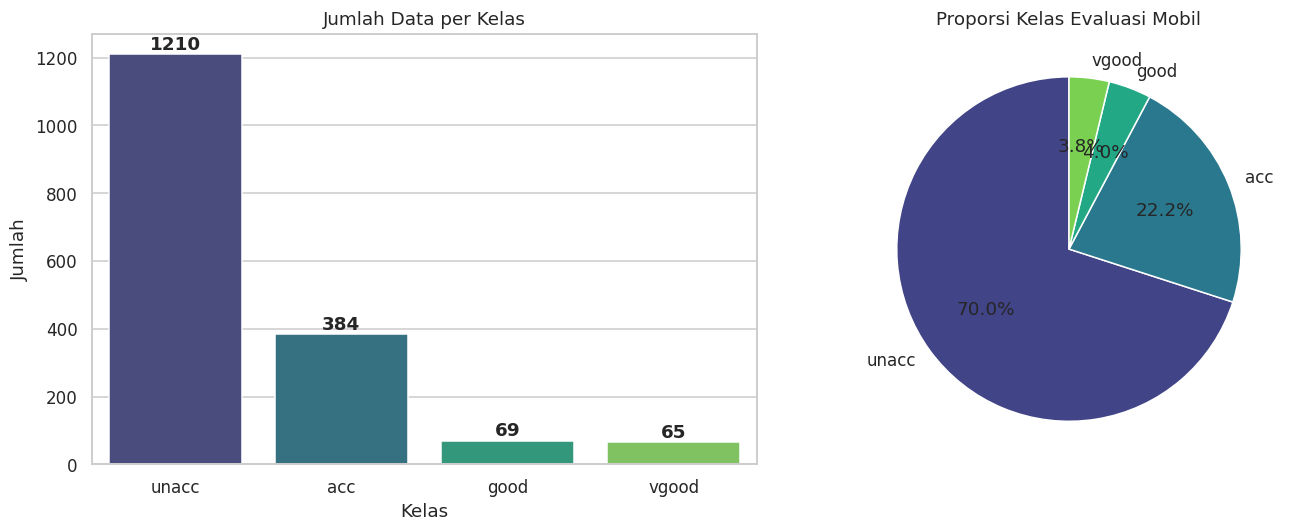

In [6]:
class_distribution = data['class'].value_counts()

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.barplot(x=class_distribution.index, y=class_distribution.values,
            ax=axes[0], hue=class_distribution.index, legend=False, palette="viridis")
axes[0].set_title('Jumlah Data per Kelas')
axes[0].set_xlabel('Kelas')
axes[0].set_ylabel('Jumlah')
for i, v in enumerate(class_distribution.values):
    axes[0].text(i, v + 15, str(v), ha='center', fontweight='bold')

axes[1].pie(class_distribution.values, labels=class_distribution.index,
            autopct='%1.1f%%', startangle=90,
            colors=sns.color_palette("viridis", len(class_distribution)))
axes[1].set_title('Proporsi Kelas Evaluasi Mobil')

plt.tight_layout()
plt.show()

### 3.2 Distribusi Setiap Fitur

Karena semua fitur bersifat kategorikal, kita lihat sebaran nilai masing-masing
fitur — dan sekaligus memastikan datasetnya seimbang secara desain (hasil dari
kombinasi penuh semua kategori atribut).

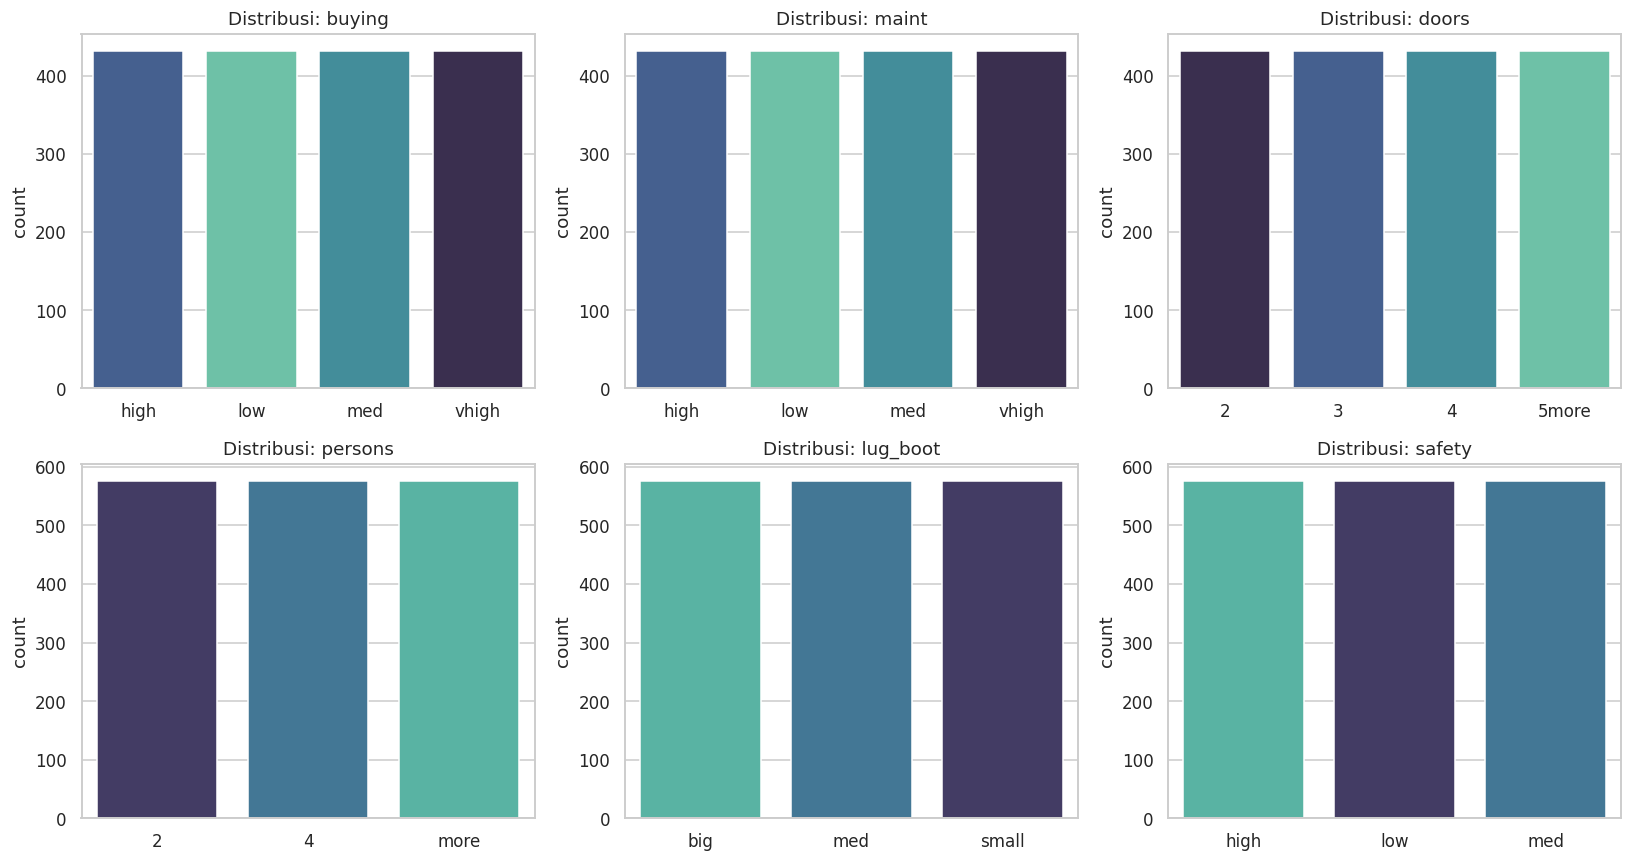

In [7]:
features = ['buying', 'maint', 'doors', 'persons', 'lug_boot', 'safety']

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, feat in zip(axes.flatten(), features):
    order = sorted(data[feat].unique())
    sns.countplot(x=feat, data=data, order=order, ax=ax,
                  hue=feat, legend=False, palette="mako")
    ax.set_title(f'Distribusi: {feat}')
    ax.set_xlabel('')
plt.tight_layout()
plt.show()

### 3.3 Hubungan Fitur `safety` & `persons` terhadap Kelas

Sebagai contoh eksplorasi hubungan antar variabel, kita lihat bagaimana tingkat
keamanan (`safety`) dan kapasitas penumpang (`persons`) memengaruhi hasil
evaluasi mobil. Intuisinya: mobil dengan keamanan rendah cenderung otomatis
`unacc`, apapun atribut lainnya.

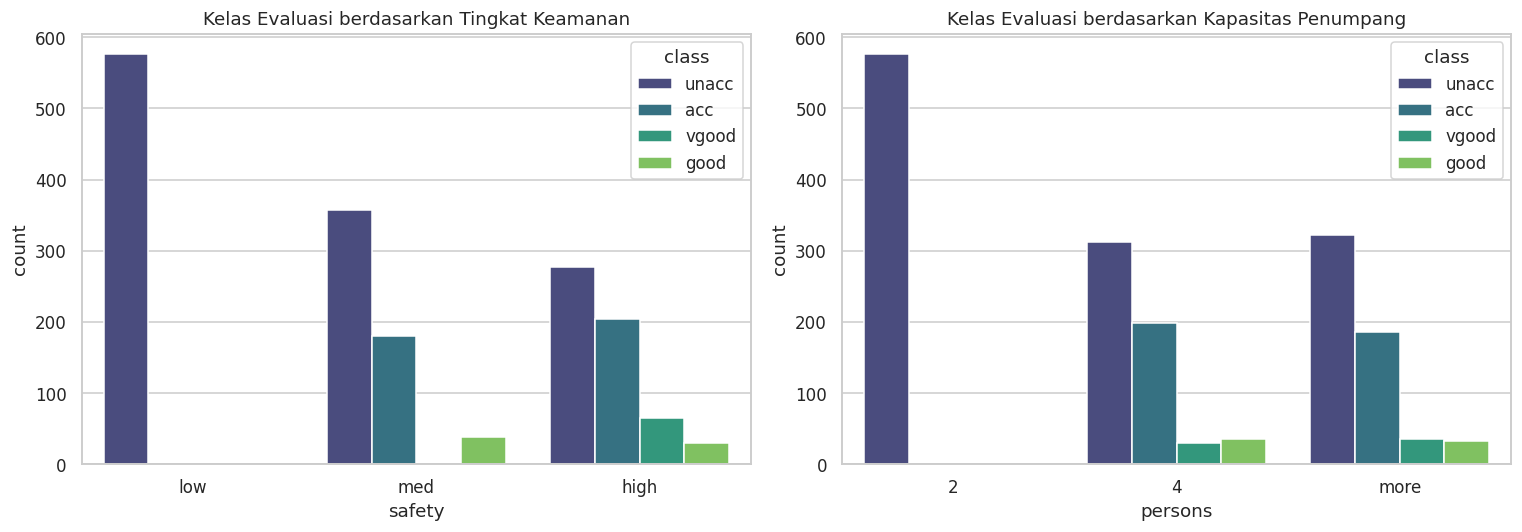

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.countplot(x='safety', hue='class', data=data, ax=axes[0],
              order=['low', 'med', 'high'], palette="viridis")
axes[0].set_title('Kelas Evaluasi berdasarkan Tingkat Keamanan')

sns.countplot(x='persons', hue='class', data=data, ax=axes[1],
              order=['2', '4', 'more'], palette="viridis")
axes[1].set_title('Kelas Evaluasi berdasarkan Kapasitas Penumpang')

plt.tight_layout()
plt.show()

> **Insight:** Semua mobil dengan `safety = low` selalu berakhir `unacc`,
> begitu pula mobil dengan `persons = 2` (hanya muat 2 orang). Ini
> mengindikasikan kedua fitur ini kemungkinan menjadi prediktor terkuat —
> sesuatu yang akan kita verifikasi lewat *feature importance* di bagian akhir.

## 4. Pra-pemrosesan Data

Fitur kategorikal diubah menjadi numerik menggunakan `OrdinalEncoder` dengan
urutan kategori yang **eksplisit** (bukan `LabelEncoder` acak), karena atribut
seperti `buying`, `maint`, dan `safety` memang memiliki tingkatan yang jelas
(mis. `low < med < high`). Ini menjaga makna ordinal data agar model — terutama
Decision Tree dan Random Forest — dapat memanfaatkannya secara optimal.

In [9]:
category_orders = [
    ['low', 'med', 'high', 'vhigh'],      # buying
    ['low', 'med', 'high', 'vhigh'],      # maint
    ['2', '3', '4', '5more'],             # doors
    ['2', '4', 'more'],                   # persons
    ['small', 'med', 'big'],              # lug_boot
    ['low', 'med', 'high'],               # safety
]

encoder = OrdinalEncoder(categories=category_orders)
X = encoder.fit_transform(data[features])
X = pd.DataFrame(X, columns=features)

class_order = ['unacc', 'acc', 'good', 'vgood']
y = data['class'].astype(pd.CategoricalDtype(categories=class_order, ordered=True)).cat.codes

X.head()

,buying,maint,doors,persons,lug_boot,safety
0,3.0,3.0,0.0,0.0,0.0,0.0
1,3.0,3.0,0.0,0.0,0.0,1.0
2,3.0,3.0,0.0,0.0,0.0,2.0
3,3.0,3.0,0.0,0.0,1.0,0.0
4,3.0,3.0,0.0,0.0,1.0,1.0


In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)
print(f"Data latih : {X_train.shape[0]} baris")
print(f"Data uji   : {X_test.shape[0]} baris")

Data latih : 1382 baris
Data uji   : 346 baris


## 5. Pelatihan Model

Tiga algoritma klasifikasi dilatih dan dibandingkan:

| Model | Karakteristik |
|---|---|
| **Decision Tree** | Sederhana, mudah diinterpretasi, rawan *overfitting* |
| **Random Forest** | Ensemble dari banyak decision tree, umumnya lebih stabil & akurat |
| **SVM (RBF kernel)** | Baik untuk batas keputusan non-linear, lebih lambat pada data besar |


In [11]:
models = {
    'Decision Tree': DecisionTreeClassifier(random_state=RANDOM_STATE),
    'Random Forest': RandomForestClassifier(random_state=RANDOM_STATE),
    'SVM (RBF)': SVC(kernel='rbf', random_state=RANDOM_STATE),
}

predictions = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    predictions[name] = model.predict(X_test)
    print(f"✅ {name} selesai dilatih")

✅ Decision Tree selesai dilatih
✅ Random Forest selesai dilatih
✅ SVM (RBF) selesai dilatih


Metrik yang dihitung untuk tiap model: **accuracy**, **precision**, **recall**, dan
**F1-score**. Precision, recall, dan F1 dihitung dengan rata-rata *weighted* (memperhitungkan
jumlah sampel tiap kelas). Karena kelas `good` dan `vgood` sangat kecil, **F1 macro**
(rata-rata biasa antar kelas, tanpa bobot) ditambahkan karena lebih jujur menggambarkan
performa pada kelas minoritas.

In [12]:
results = []
for name, y_pred in predictions.items():
    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred, average='weighted', zero_division=0),
        'Recall': recall_score(y_test, y_pred, average='weighted', zero_division=0),
        'F1-Score (Weighted)': f1_score(y_test, y_pred, average='weighted', zero_division=0),
        'F1-Score (Macro)': f1_score(y_test, y_pred, average='macro', zero_division=0),
    })

results_df = pd.DataFrame(results).set_index('Model').round(4)
results_df.style.background_gradient(cmap='viridis', axis=0)

,Accuracy,Precision,Recall,F1-Score (Weighted),F1-Score (Macro)
Model,,,,,
Decision Tree,0.976900,0.976600,0.976900,0.976600,0.956500
Random Forest,0.968200,0.968600,0.968200,0.968100,0.915100
SVM (RBF),0.962400,0.965800,0.962400,0.961800,0.897300


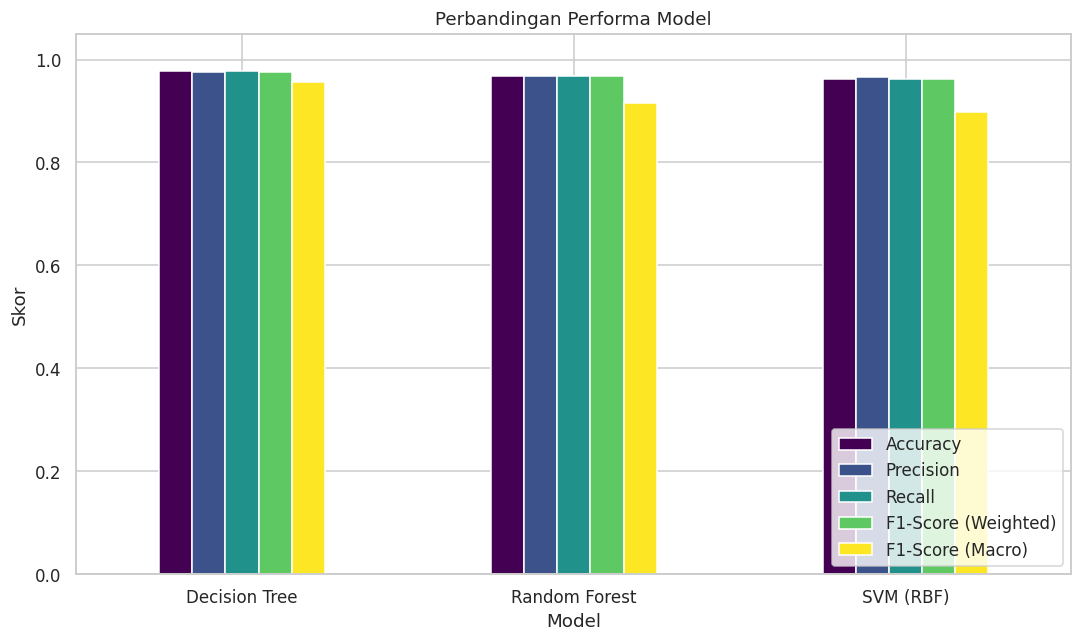

In [13]:
results_df.plot(kind='bar', figsize=(10, 6), colormap='viridis', rot=0)
plt.title('Perbandingan Performa Model')
plt.ylabel('Skor')
plt.ylim(0, 1.05)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

### Validasi Silang (Stratified 10-Fold)

Test set hanya berisi 14 sampel `good` dan 13 sampel `vgood`, sehingga selisih 1–2% antar model
pada satu kali *split* bisa jadi hanya noise. Untuk perbandingan yang lebih stabil, setiap model
dievaluasi dengan **stratified 10-fold cross-validation** pada seluruh data. Model dibuat ulang
(`clone`) di tiap fold sehingga tidak ada kebocoran dari model yang sudah dilatih sebelumnya.

In [14]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.base import clone

cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=RANDOM_STATE)

cv_rows = []
for name, model in models.items():
    scores = cross_validate(
        clone(model), X, y, cv=cv,
        scoring={'acc': 'accuracy', 'f1m': 'f1_macro'},
    )
    cv_rows.append({
        'Model': name,
        'Accuracy (mean)': scores['test_acc'].mean(),
        'Accuracy (std)': scores['test_acc'].std(),
        'F1 Macro (mean)': scores['test_f1m'].mean(),
        'F1 Macro (std)': scores['test_f1m'].std(),
    })

cv_df = pd.DataFrame(cv_rows).set_index('Model').round(4)
cv_df

,Accuracy (mean),Accuracy (std),F1 Macro (mean),F1 Macro (std)
Model,,,,
Decision Tree,0.9838,0.0092,0.9597,0.0278
Random Forest,0.9850,0.0069,0.9593,0.0257
SVM (RBF),0.9653,0.0113,0.9366,0.0355


Jika selisih rata-rata antar model lebih kecil daripada simpangan baku (*std*) antar fold,
perbedaan tersebut tidak bisa dianggap bermakna secara praktis.

Grafik di bawah merangkum hasil cross-validation dan disimpan ke `images/model_comparison.png`
(dipakai di `README.md`). Sumbu Y dimulai dari 0 agar selisih antar model tidak terlihat
lebih besar dari aslinya, dan *error bar* menunjukkan simpangan baku antar fold.

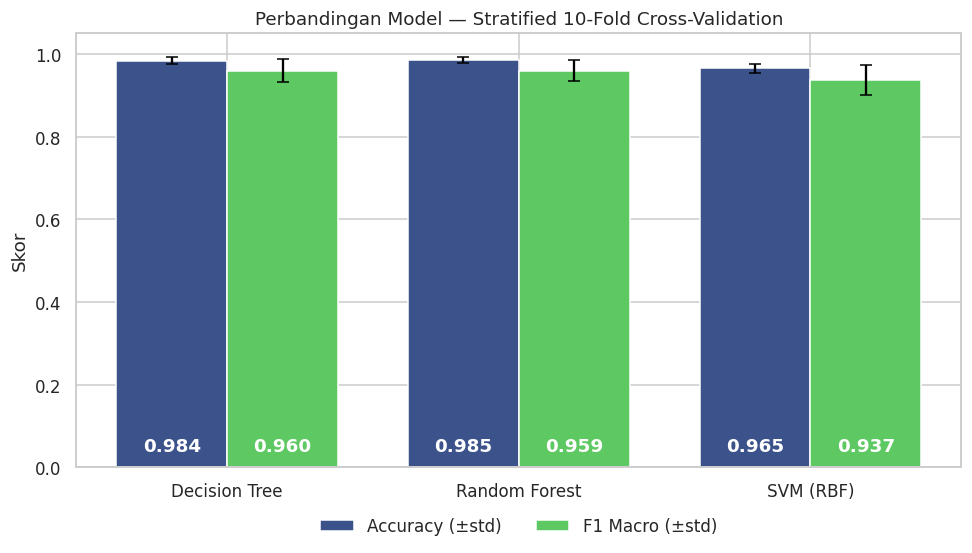

In [15]:
import os

fig, ax = plt.subplots(figsize=(9, 5.2))

x = np.arange(len(cv_df))
w = 0.38

bars_acc = ax.bar(x - w/2, cv_df['Accuracy (mean)'], w, yerr=cv_df['Accuracy (std)'],
                  capsize=4, label='Accuracy (±std)', color=sns.color_palette('viridis', 3)[0])
bars_f1 = ax.bar(x + w/2, cv_df['F1 Macro (mean)'], w, yerr=cv_df['F1 Macro (std)'],
                 capsize=4, label='F1 Macro (±std)', color=sns.color_palette('viridis', 3)[2])

for bars in (bars_acc, bars_f1):
    for b in bars:
        ax.text(b.get_x() + b.get_width()/2, 0.03, f'{b.get_height():.3f}',
                ha='center', va='bottom', color='white', fontweight='bold')

ax.set_xticks(x)
ax.set_xticklabels(cv_df.index)
ax.set_ylim(0, 1.05)
ax.set_ylabel('Skor')
ax.set_title('Perbandingan Model — Stratified 10-Fold Cross-Validation')
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.08), ncol=2, frameon=False)

plt.tight_layout()
os.makedirs('../images', exist_ok=True)
plt.savefig('../images/model_comparison.png', dpi=130, bbox_inches='tight')
plt.show()

### Laporan Klasifikasi Detail per Model

`classification_report` menampilkan precision, recall, dan F1-score **per
kelas** — penting di sini karena kelas `good` dan `vgood` jumlah datanya jauh
lebih sedikit, sehingga performa rata-rata bisa menutupi kelemahan model pada
kelas minoritas tersebut.

In [16]:
for name, y_pred in predictions.items():
    print(f"{'='*55}\n{name}\n{'='*55}")
    print(classification_report(y_test, y_pred, target_names=class_order, zero_division=0))

Decision Tree
              precision    recall  f1-score   support

       unacc       0.98      1.00      0.99       242
         acc       0.96      0.94      0.95        77
        good       0.92      0.86      0.89        14
       vgood       1.00      1.00      1.00        13

    accuracy                           0.98       346
   macro avg       0.97      0.95      0.96       346
weighted avg       0.98      0.98      0.98       346

Random Forest
              precision    recall  f1-score   support

       unacc       0.99      0.99      0.99       242
         acc       0.92      0.95      0.94        77
        good       0.92      0.79      0.85        14
       vgood       0.86      0.92      0.89        13

    accuracy                           0.97       346
   macro avg       0.92      0.91      0.92       346
weighted avg       0.97      0.97      0.97       346

SVM (RBF)
              precision    recall  f1-score   support

       unacc       1.00      0.98    

## 7. Confusion Matrix

Visualisasi confusion matrix membantu melihat *jenis kesalahan* tiap model —
misalnya apakah model sering salah mengklasifikasikan `acc` sebagai `unacc`.

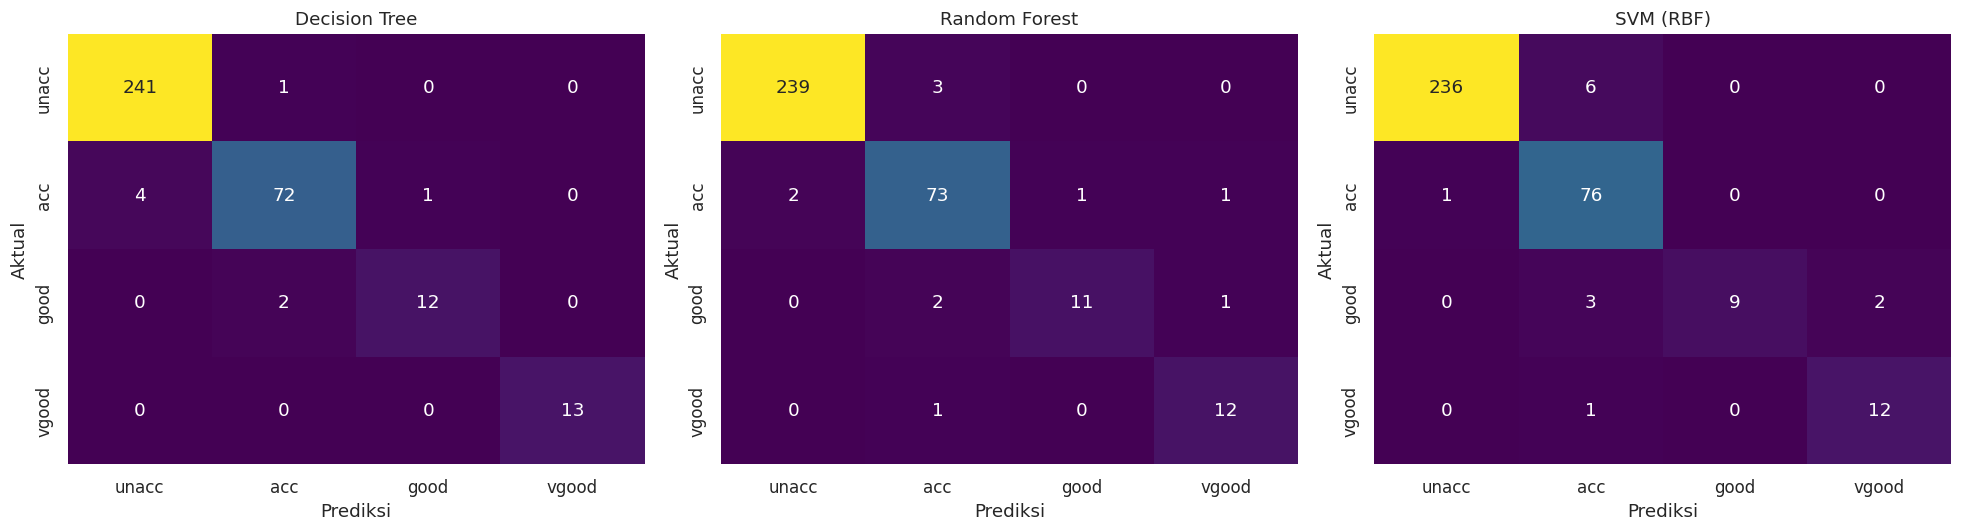

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (name, y_pred) in zip(axes, predictions.items()):
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='viridis',
                xticklabels=class_order, yticklabels=class_order, ax=ax, cbar=False)
    ax.set_title(name)
    ax.set_xlabel('Prediksi')
    ax.set_ylabel('Aktual')

plt.tight_layout()
plt.show()

## 8. Feature Importance

Untuk model berbasis pohon (Decision Tree & Random Forest), kita bisa melihat
fitur mana yang paling berkontribusi terhadap keputusan klasifikasi —
memverifikasi dugaan awal dari tahap EDA.

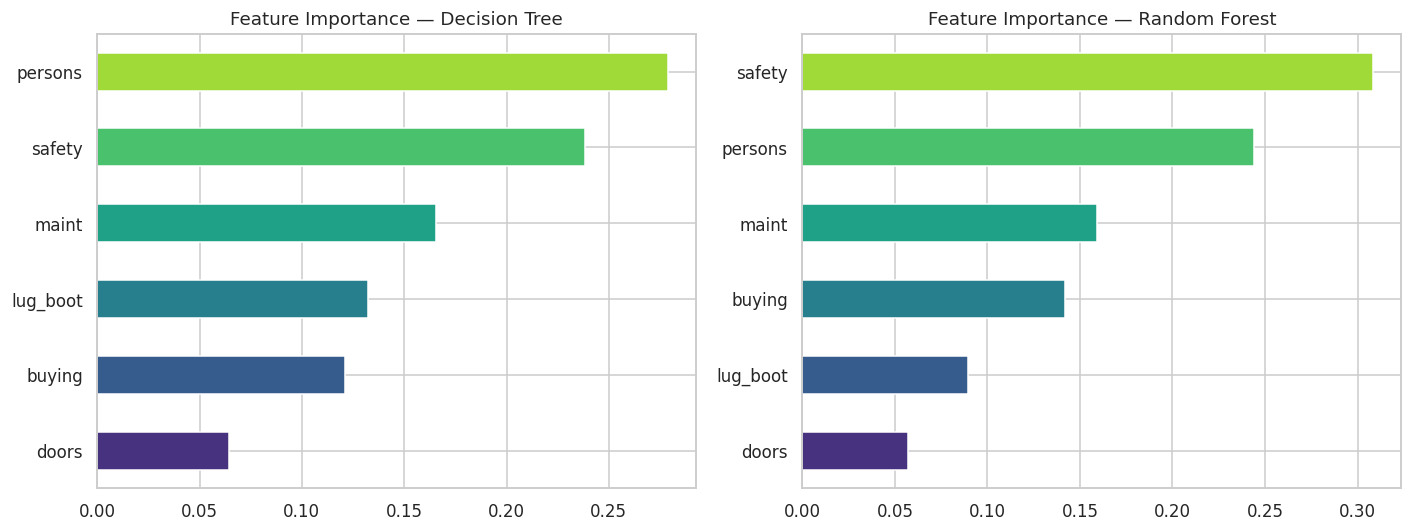

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

tree_importance = pd.Series(models['Decision Tree'].feature_importances_, index=features).sort_values()
rf_importance = pd.Series(models['Random Forest'].feature_importances_, index=features).sort_values()

tree_importance.plot(kind='barh', ax=axes[0], color=sns.color_palette("viridis", len(features)))
axes[0].set_title('Feature Importance — Decision Tree')

rf_importance.plot(kind='barh', ax=axes[1], color=sns.color_palette("viridis", len(features)))
axes[1].set_title('Feature Importance — Random Forest')

plt.tight_layout()
plt.show()

## 9. Kesimpulan

- **`persons`** dan **`safety`** adalah dua fitur paling penting di kedua model berbasis pohon
  (Random Forest: `safety` ≈ 0,31 dan `persons` ≈ 0,24) — sejalan dengan pola EDA bahwa
  `safety = low` dan `persons = 2` selalu menghasilkan `unacc`.
- **Decision Tree dan Random Forest berperforma setara.** Pada satu kali split, Decision Tree
  sedikit unggul (akurasi 0,977 vs 0,968; F1 macro 0,957 vs 0,915). Pada 10-fold CV, keduanya
  hampir identik (akurasi 0,984 vs 0,985; F1 macro 0,960 vs 0,959) dengan selisih jauh di bawah
  simpangan baku antar fold, sehingga **tidak ada pemenang yang jelas**.
- **SVM (RBF, parameter default) sedikit tertinggal** (akurasi CV 0,965; F1 macro 0,937),
  terutama karena recall kelas `good` rendah (0,64 pada test set). Parameter `C` dan `gamma`
  belum dituning, jadi hasil ini belum tentu batas atas SVM.
- Karena kelas `good` dan `vgood` sangat kecil (14 dan 13 sampel di test set), **F1 macro dan
  laporan per kelas lebih informatif daripada accuracy global**, dan perbandingan satu kali split
  mudah menyesatkan.
- Dataset ini dihasilkan dari kombinasi penuh atribut dengan aturan keputusan deterministik,
  sehingga skor tinggi di sini tidak otomatis berarti model akan sebaik itu pada data dunia nyata.

**Kemungkinan pengembangan lebih lanjut:**
- Hyperparameter tuning (`GridSearchCV`) untuk ketiga model, terutama `C` dan `gamma` pada SVM.
- Menangani ketidakseimbangan kelas (mis. `class_weight='balanced'` atau SMOTE) untuk menaikkan recall `good`.
- Membandingkan model tambahan, misalnya Gradient Boosting / XGBoost.
